# Project Name

## Motivation

Depression is common among university students and often worsens over the course of a term as
academic pressure builds. Many struggling students do not seek help on their own, and
universities usually learn about them only after warning signs appear: missed classes, falling
grades, or a crisis.

Identifying students who may experience elevated depressive symptoms later in the term could help
universities offer support before symptoms escalate. Start-of-term depression, loneliness, and
flourishing surveys are short, inexpensive, and already validated, and may provide useful
information about students' subsequent mental health.

Beyond the institutional benefit, this is a public interest goal, since earlier support can reduce
suffering, protect academic progress, and make better use of counselling services that are often
over capacity.

## Objective

Evaluate whether start-of-term depression, loneliness, and flourishing scores can predict end-of-term PHQ-9 depression scores. Compare a model using baseline depression alone with a model that also includes loneliness and flourishing.

## Research question

Do start-of-term loneliness and flourishing scores improve prediction of end-of-term depressive symptom severity beyond start-of-term depression scores?

## Business value

The study could provide preliminary evidence about whether adding loneliness and flourishing questionnaires improves universities’ ability to identify future support needs beyond a baseline depression survey. This could inform the design of screening and outreach programs, subject to larger-scale validation.

## Who uses the solution and how

**Primary users:** university counselling and student wellness services.

**Workflow:**
1. At the start of term, students voluntarily complete a short survey (PHQ-9, UCLA Loneliness,
   Flourishing), for example during orientation or in a first-week check-in.
2. The model scores each student once and flags those predicted to be at risk of clinically
   significant symptoms by the end of term.
3. Wellness staff reach out to flagged students with low-intensity support (a check-in, workshop
   invitation, or information about counselling) before the busy mid-term period.

**Important boundaries:** the model is a **screening aid, not a diagnosis**. It only prioritizes
outreach; all decisions stay with trained staff. Any student who reports thoughts of self-harm
(PHQ-9 item 9) should be followed up immediately, regardless of the model's prediction.
Participation must be voluntary, with informed consent and confidential handling of responses.

## Current solutions and workarounds

- **Self-referral:** students contact counselling services themselves. This misses students who
  do not recognize their symptoms or avoid seeking help.
- **Reactive identification:** professors, advisors, or residence staff notice warning signs
  (absences, falling grades), usually after symptoms are already severe.
- **One-off screening with a fixed cutoff:** some institutions screen with the PHQ-9 and flag
  scores ≥ 10. This only captures students who are *already* symptomatic and misses those who
  will get worse.

Our baseline reproduces the third approach. In the training data, the simple rule
"flag PHQ-9 ≥ 10 at start of term" missed 2 of 6 at-risk students, both of whom worsened during
the term. Our model is useful only if it improves on this rule.

## Framing the problem

| Decision | Choice | Justification |
|---|---|---|
| Learning type | **Supervised** | We observe the true end-of-term PHQ-9 score for every student, so we can learn a mapping from start-of-term surveys to a known outcome. |
| Task type | **Regression** (primary) and **binary classification** (secondary) | The score preserves full information about severity; the at-risk label (PHQ-9 ≥ 10) matches the real decision of whom to contact. |
| Training mode | **Offline (batch) learning** | Data arrives once per term, in a single survey wave; there is no continuous data stream to justify online learning. The model would be retrained each year as new survey data is collected. |
| Prediction mode | **Batch prediction** | All students are scored once at the start of term, not in real time. |
| Unit of analysis | One row per student | Each student's start-of-term scores (X) are paired with their own end-of-term outcome (y). |

## How Performance Is Measured

- **Regression:** RMSE (penalizes large misses, such as under-predicting a severe case) and MAE
  (average error in PHQ-9 points, easy to interpret). Both are compared against two baselines:
  predicting the training mean, and the start-of-term score alone.
- **Classification:** **Recall** for the at-risk class is our priority metric, because missing a
  student who will struggle (false negative) is costlier than an extra check-in (false positive).
  We also report precision and ROC-AUC, and compare against the PHQ-9 ≥ 10 screening rule.
- **Evaluation:** repeated k-fold cross-validation on the training set (mean ± standard
  deviation), with a single final evaluation on the held-out test set.

**Alignment with the objective:** the goal is to reach struggling students early, so the metrics
reward catching at-risk students (recall) and accurately estimating severity (RMSE/MAE), rather
than overall accuracy. Accuracy would be misleading here: a model that predicts "not at risk"
for everyone would be 82% accurate while helping no one.

In [63]:
import sys

assert sys.version_info >= (3, 7)

In [64]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

### Data Acquisition

We are using the StudentLife dataset, accessed through Kaggle. The data originated from a Dartmouth College study conducted during the spring term of 2013, following 48 students over 10 weeks. The study examined students’ mental health, academic performance, and behavioral patterns using smartphone sensing and surveys.

Students completed mental health questionnaires at the beginning and end of the study. This longitudinal structure allows us to investigate whether information collected at the start of term can predict depressive symptoms at the end. Our project focuses on three survey files from the same study.

In [65]:
%pip install "kagglehub[pandas-datasets]"

import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd

def load_studentlife_data(file_name):
    return kagglehub.dataset_load(
        KaggleDatasetAdapter.PANDAS,
        "dartweichen/student-life",
        f"dataset/survey/{file_name}"
    )

Note: you may need to restart the kernel to use updated packages.


#### **Selected Survey Files**

1. PHQ-9.csv — Depressive Symptoms

The **Patient Health Questionnaire-9 (PHQ-9)** measures depressive symptom severity through nine items. Using standard scoring, the total ranges from **0 to 27**, with higher scores indicating greater symptom severity.

**How we will use it:**

- **Pre-survey PHQ-9 score:** Predictor representing baseline depressive symptoms.
- **Post-survey PHQ-9 score:** Target representing end-of-term depressive symptoms.

**Why we selected it:**  
Baseline depression provides a benchmark for predicting later symptoms. Including it allows us to assess whether loneliness and flourishing improve prediction beyond what is already explained by initial depression scores.

In [66]:
phq9_df = load_studentlife_data("PHQ-9.csv")
phq9_df.head()

,uid,type,Little interest or pleasure in doing things,"Feeling down, depressed, hopeless.","Trouble falling or staying asleep, or sleeping too much.",Feeling tired or having little energy,Poor appetite or overeating,Feeling bad about yourself or that you are a failure or have let yourself or your family down,"Trouble concentrating on things, such as reading the newspaper or watching television",Moving or speaking so slowly that other people could have noticed. Or the opposite being so figety or restless that you have been moving around a lot more than usual,"Thoughts that you would be better off dead, or of hurting yourself",Response
0,u00,pre,Not at all,Several days,Not at all,Several days,Not at all,Not at all,Not at all,Not at all,Not at all,Not difficult at all
1,u01,pre,Several days,Several days,Several days,Several days,Not at all,Several days,Not at all,Not at all,Not at all,Very difficult
2,u02,pre,More than half the days,Several days,More than half the days,More than half the days,More than half the days,Several days,Several days,More than half the days,Not at all,Somewhat difficult
3,u03,pre,Not at all,Several days,Not at all,Not at all,Not at all,Not at all,Not at all,Several days,Not at all,Somewhat difficult
4,u04,pre,Several days,Several days,Not at all,Several days,Several days,Several days,Several days,Not at all,Not at all,Somewhat difficult


2. LonelinessScale.csv — Perceived Loneliness

The **UCLA Loneliness Scale** measures perceived loneliness and social isolation. Higher scores indicate greater loneliness after applying the published scoring method.

**How we will use it:**

- Use only the **pre-survey loneliness score** as a predictor.

**Why we selected it:**  
This measure allows us to test whether students’ perceived social disconnection adds predictive information about end-of-term depressive symptoms beyond baseline depression.

In [67]:
loneliness_df = load_studentlife_data("LonelinessScale.csv")
loneliness_df.head()

,uid,type,1. I feel in tune with the people around me,2. I lack companionship,3. There is no one I can turn to,4. I do not feel alone,5. I feel part of a group of friends,6. I have a lot in common with the people around me,7. I am no longer close to anyone,8. My interests and ideas are not shared by those around me,...,11. I feel left out,12. My social relationships are superficial,13. No one really knows me well,14. I feel isolated from others,15. I can find companionship when I want it,16. There are people who really understand me,17. I am unhappy being so withdrawn,18. People are around me but not with me,19. There are people I can talk to,20. There are people I can turn to
0,u00,pre,Sometimes,Rarely,Never,Never,Often,Sometimes,Never,Never,...,Rarely,Rarely,Never,Never,Often,Rarely,Often,Sometimes,Often,Often
1,u01,pre,Sometimes,Rarely,Rarely,Sometimes,Often,Often,Never,Never,...,Rarely,Rarely,Never,Rarely,Often,Often,Sometimes,Never,Often,Often
2,u02,pre,Sometimes,Rarely,Rarely,Often,Often,Often,Never,Often,...,Rarely,Never,Never,Never,Often,Often,Never,Never,Often,Often
3,u03,pre,Sometimes,Rarely,Never,Often,Rarely,Rarely,Sometimes,Sometimes,...,Rarely,Rarely,Sometimes,Sometimes,Sometimes,Often,Sometimes,Sometimes,Sometimes,Sometimes
4,u04,pre,Sometimes,Sometimes,Sometimes,Sometimes,Rarely,Sometimes,Never,Rarely,...,Sometimes,Sometimes,Sometimes,Sometimes,Rarely,Rarely,Sometimes,Sometimes,Rarely,Rarely


3. FlourishingScale.csv — Psychological Well-Being

The **Flourishing Scale** measures psychological well-being through eight items covering areas such as relationships, purpose, self-esteem, and optimism. Standard total scores range from **8 to 56**, with higher scores indicating greater flourishing.

**How we will use it:**

- Use only the **pre-survey flourishing score** as a predictor.

**Why we selected it:**  
Flourishing adds a positive well-being perspective, complementing the symptom-focused depression and loneliness measures. We will assess whether it improves prediction of end-of-term depressive symptoms.


In [68]:
flourishing_df = load_studentlife_data("FlourishingScale.csv")
flourishing_df.head()

,uid,type,I lead a purposeful and meaningful life,My social relationships are supportive and rewarding,I am engaged and interested in my daily activities,I actively contribute to the happiness and well-being of others,I am competent and capable in the activities that are important to me,I am a good person and live a good life,I am optimistic about my future,People respect me
0,u00,pre,7,6,NaN,6.0,6.0,7.0,7,4
1,u01,pre,4,6,6.0,6.0,7.0,6.0,4,6
2,u02,pre,6,7,5.0,6.0,5.0,6.0,4,7
3,u03,pre,6,2,2.0,4.0,5.0,6.0,5,4
4,u04,pre,3,5,4.0,3.0,2.0,2.0,3,5


### Data Exploration and Cleaning

1. PHQ-9.csv — Depressive Symptoms

In [69]:
print(phq9_df.shape)
phq9_df.info()

(84, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84 entries, 0 to 83
Data columns (total 12 columns):
 #   Column                                                                                                                                                                 Non-Null Count  Dtype 
---  ------                                                                                                                                                                 --------------  ----- 
 0   uid                                                                                                                                                                    84 non-null     object
 1   type                                                                                                                                                                   84 non-null     object
 2   Little interest or pleasure in doing things                                                            

In [70]:
# Missing values by column
missing_summary = pd.DataFrame({
    "MissingCount": phq9_df.isna().sum(),
    "MissingPercent": phq9_df.isna().mean() * 100
})

display(missing_summary)

# Exact duplicate rows
print("Duplicate rows:", phq9_df.duplicated().sum())

,MissingCount,MissingPercent
uid,0,0.000000
type,0,0.000000
Little interest or pleasure in doing things,0,0.000000
"Feeling down, depressed, hopeless.",0,0.000000
"Trouble falling or staying asleep, or sleeping too much.",0,0.000000
Feeling tired or having little energy,0,0.000000
Poor appetite or overeating,0,0.000000
Feeling bad about yourself or that you are a failure or have let yourself or your family down,0,0.000000
"Trouble concentrating on things, such as reading the newspaper or watching television",0,0.000000
Moving or speaking so slowly that other people could have noticed. Or the opposite being so figety or restless that you have been moving around a lot more than usual,0,0.000000


Duplicate rows: 0


In [71]:
phq9_df['type'].value_counts()

type
pre     46
post    38
Name: count, dtype: int64

In [72]:
# Check duplicate student + survey period combinations
print(
    "Duplicate student-period combinations:",
    phq9_df.duplicated(subset=["uid", "type"]).sum()
)

Duplicate student-period combinations: 0


In [73]:
# Count unique students and students with both survey periods
print("Unique students:", phq9_df["uid"].nunique())

survey_counts = pd.crosstab(phq9_df["uid"], phq9_df["type"])
print(
    "Students with both pre and post:",
    ((survey_counts["pre"] > 0) & (survey_counts["post"] > 0)).sum()
)

Unique students: 46
Students with both pre and post: 38


In [74]:
# Inspect answer categories across the nine symptom items
item_columns = phq9_df.columns[2:11]

display(
    phq9_df[item_columns]
    .melt(value_name="Answer")["Answer"]
    .value_counts(dropna=False)
)

Answer
Not at all                 412
Several days               234
More than half the days     72
Nearly every day            38
Name: count, dtype: int64

In [75]:
# Inspect the additional Response column
display(phq9_df["Response"].value_counts(dropna=False))

Response
Somewhat difficult      37
Not difficult at all    36
NaN                      5
Very difficult           3
Extremely difficult      3
Name: count, dtype: int64

**Findings and Data Cleaning Plan**

- The dataset contains 84 survey responses from 46 students: 46 pre-surveys and 38 post-surveys. We will retain the 38 students who completed both surveys for modeling because we need each student’s baseline predictors and observed end-of-term outcome to train and evaluate the model.
- We will match pre- and post-survey responses using `uid`. The 8 students without post-survey outcomes will be excluded from modeling; their missing outcomes will not be imputed.
- All nine symptom questions are complete. The additional `Response` column has 5 missing values (5.95%), but it is excluded from the PHQ-9 total, so these missing values will not cause any rows to be dropped.
- We will encode the nine symptom responses from 0 to 3 and sum them to calculate the standard PHQ-9 total (0–27).
- Pre-survey scores will serve as predictors, and post-survey PHQ-9 scores will serve as the outcome.

In [76]:
# Create a working copy of the raw PHQ-9 data and standardize IDs and survey labels
# (same cleaning applied to the loneliness and flourishing tables)
phq9_clean = phq9_df.copy()

phq9_clean["uid"] = phq9_clean["uid"].str.strip()
phq9_clean["type"] = phq9_clean["type"].str.strip().str.lower()

In [77]:
from sklearn.preprocessing import OrdinalEncoder

# Select the nine symptom questions
item_columns = phq9_df.columns[2:11]

# Define the scoring order: 0, 1, 2, 3
response_order = [
    "Not at all",
    "Several days",
    "More than half the days",
    "Nearly every day"
]

encoder = OrdinalEncoder(
    categories=[response_order for _ in item_columns],
    dtype=int
)

# Encode the nine symptom questions
phq9_clean[item_columns] = encoder.fit_transform(
    phq9_df[item_columns].apply(lambda column: column.str.strip())
)

# Calculate the total score
phq9_clean["phq9_total"] = phq9_clean[item_columns].sum(
    axis=1, min_count=9
)

phq9_clean.head()

,uid,type,Little interest or pleasure in doing things,"Feeling down, depressed, hopeless.","Trouble falling or staying asleep, or sleeping too much.",Feeling tired or having little energy,Poor appetite or overeating,Feeling bad about yourself or that you are a failure or have let yourself or your family down,"Trouble concentrating on things, such as reading the newspaper or watching television",Moving or speaking so slowly that other people could have noticed. Or the opposite being so figety or restless that you have been moving around a lot more than usual,"Thoughts that you would be better off dead, or of hurting yourself",Response,phq9_total
0,u00,pre,0,1,0,1,0,0,0,0,0,Not difficult at all,2
1,u01,pre,1,1,1,1,0,1,0,0,0,Very difficult,5
2,u02,pre,2,1,2,2,2,1,1,2,0,Somewhat difficult,13
3,u03,pre,0,1,0,0,0,0,0,1,0,Somewhat difficult,2
4,u04,pre,1,1,0,1,1,1,1,0,0,Somewhat difficult,6


In [78]:
# Create one row per student with separate pre and post scores
phq9_paired = (
    phq9_clean.pivot(
        index="uid",
        columns="type",
        values="phq9_total"
    )
    .rename(columns={
        "pre": "phq9_pre",
        "post": "phq9_post"
    })
    .rename_axis(columns=None)
    .reset_index()
)

# Exclude students without both scores
phq9_paired = phq9_paired.dropna(
    subset=["phq9_pre", "phq9_post"]
).reset_index(drop=True)

# Verify the result
print("Students retained:", len(phq9_paired))
display(phq9_paired.head())

Students retained: 38


,uid,phq9_post,phq9_pre
0,u00,3.0,2.0
1,u01,4.0,5.0
2,u02,5.0,13.0
3,u03,4.0,2.0
4,u04,8.0,6.0


2. LonelinessScale.csv — Perceived Loneliness

In [79]:
print("Shape:", loneliness_df.shape)
loneliness_df.info()

Shape: (83, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83 entries, 0 to 82
Data columns (total 22 columns):
 #   Column                                                       Non-Null Count  Dtype 
---  ------                                                       --------------  ----- 
 0   uid                                                          83 non-null     object
 1   type                                                         83 non-null     object
 2   1. I feel in tune with the people around me                  83 non-null     object
 3   2. I lack companionship                                      83 non-null     object
 4   3. There is no one I can turn to                             83 non-null     object
 5   4. I do not feel alone                                       83 non-null     object
 6   5. I feel part of a group of friends                         83 non-null     object
 7   6. I have a lot in common with the people around me          83 non-null   

In [80]:
# Check survey periods
display(loneliness_df["type"].value_counts(dropna=False))

# Check duplicates
print("Duplicate rows:", loneliness_df.duplicated().sum())
print(
    "Duplicate student-period combinations:",
    loneliness_df.duplicated(subset=["uid", "type"]).sum()
)

type
pre     46
post    37
Name: count, dtype: int64

Duplicate rows: 0
Duplicate student-period combinations: 0


In [81]:
# Inspect response categories for each question
for column in loneliness_df.columns:
    if column not in ["uid", "type"]:
        print(f"\n{column}:")
        print(loneliness_df[column].value_counts(dropna=False).to_string())


1. I feel in tune with the people around me:
1. I feel in tune with the people around me
Sometimes    42
Often        31
Rarely       10

2. I lack companionship:
2. I lack companionship
Rarely       35
Sometimes    26
Never        14
Often         8

3. There is no one I can turn to:
3. There is no one I can turn to
Never        38
Rarely       24
Sometimes    16
Often         5

4. I do not feel alone:
4. I do not feel alone
Often        45
Sometimes    24
Rarely       10
Never         4

5. I feel part of a group of friends:
5. I feel part of a group of friends
Often        45
Sometimes    22
Rarely       12
Never         4

6. I have a lot in common with the people around me:
6. I have a lot in common with the people around me
Often        34
Sometimes    28
Rarely       17
Never         4

7. I am no longer close to anyone:
7. I am no longer close to anyone
Never        41
Rarely       20
Sometimes    15
Often         7

8. My interests and ideas are not shared by those around me

In [82]:
# Preserve the original data
loneliness_clean = loneliness_df.copy()

# Standardize identifiers and survey labels
loneliness_clean["uid"] = loneliness_clean["uid"].str.strip()
loneliness_clean["type"] = (
    loneliness_clean["type"].str.strip().str.lower()
)

# Keep only baseline responses
loneliness_clean = loneliness_clean.loc[
    loneliness_clean["type"] == "pre"
].copy()

# Select the 20 survey questions
loneliness_items = [
    column for column in loneliness_clean.columns
    if column not in ["uid", "type"]
]

# Inspect all baseline answer categories
display(
    loneliness_clean[loneliness_items]
    .melt(value_name="Answer")["Answer"]
    .value_counts(dropna=False)
)

print("Baseline responses retained:", len(loneliness_clean))

Answer
Sometimes    290
Often        262
Rarely       216
Never        152
Name: count, dtype: int64

Baseline responses retained: 46


**Findings and Data Cleaning Plan**

- The dataset contains 83 survey responses: 46 pre-surveys and 37 post-surveys, with 20 questionnaire items.
- No missing values, duplicate rows, or duplicate student–survey period combinations were found.
- We will retain only the 46 pre-survey responses, because baseline loneliness will be used to predict end-of-term PHQ-9 scores. Post-survey loneliness responses are not required.
- We will remove extra spaces from student IDs and response labels to ensure consistent encoding and matching.
- We will encode responses in their ordered categories and reverse-score the appropriate items so that higher scores consistently indicate greater loneliness.
- We will calculate the total loneliness score using all 20 correctly scored items and check for missing scores and values outside the expected range.
- We will retain `uid` and `loneliness_pre` for merging with the PHQ-9 table. Only students with the required observed PHQ-9 outcome will enter supervised modeling.

In [83]:
# Create a copy and standardize IDs and survey labels
loneliness_clean = loneliness_df.copy()

loneliness_clean["uid"] = loneliness_clean["uid"].str.strip()
loneliness_clean["type"] = (
    loneliness_clean["type"].str.strip().str.lower()
)

In [84]:
# keep only pre survey response
loneliness_clean = loneliness_clean.loc[
    loneliness_clean["type"] == "pre"
].copy()

print("Baseline students retained:", len(loneliness_clean))

Baseline students retained: 46


In [85]:
# Select the 20 questions and clean response labels
loneliness_items = [
    column for column in loneliness_clean.columns
    if column not in ["uid", "type"]
]

loneliness_clean[loneliness_items] = (
    loneliness_clean[loneliness_items]
    .apply(lambda column: column.str.strip())
)

In [86]:
# Check for missing responses and duplicate students
assert len(loneliness_items) == 20, "Expected 20 questions."

assert loneliness_clean["uid"].notna().all(), \
    "Missing student IDs."

assert not loneliness_clean["uid"].duplicated().any(), \
    "Duplicate baseline responses."

assert loneliness_clean[loneliness_items].notna().all().all(), \
    "Missing questionnaire responses."

In [87]:
# Encode responses from 1 to 4
from sklearn.preprocessing import OrdinalEncoder

response_order = ["Never", "Rarely", "Sometimes", "Often"]

loneliness_encoder = OrdinalEncoder(
    categories=[response_order for _ in loneliness_items],
    dtype=int
)

loneliness_clean[loneliness_items] = (
    loneliness_encoder.fit_transform(
        loneliness_clean[loneliness_items]
    ) + 1
)

In [88]:
# Reverse-score the positively worded questions
reverse_numbers = {1, 4, 5, 6, 9, 10, 15, 16, 19, 20}

reverse_columns = [
    column for column in loneliness_items
    if int(column.split(".")[0].strip()) in reverse_numbers
]

assert len(reverse_columns) == 10, \
    "Check reverse-scored column names."

loneliness_clean[reverse_columns] = (
    5 - loneliness_clean[reverse_columns]
)

In [89]:
loneliness_clean.head()

,uid,type,1. I feel in tune with the people around me,2. I lack companionship,3. There is no one I can turn to,4. I do not feel alone,5. I feel part of a group of friends,6. I have a lot in common with the people around me,7. I am no longer close to anyone,8. My interests and ideas are not shared by those around me,...,11. I feel left out,12. My social relationships are superficial,13. No one really knows me well,14. I feel isolated from others,15. I can find companionship when I want it,16. There are people who really understand me,17. I am unhappy being so withdrawn,18. People are around me but not with me,19. There are people I can talk to,20. There are people I can turn to
0,u00,pre,2,2,1,4,1,2,1,1,...,2,2,1,1,1,3,4,3,1,1
1,u01,pre,2,2,2,2,1,1,1,1,...,2,2,1,2,1,1,3,1,1,1
2,u02,pre,2,2,2,1,1,1,1,4,...,2,1,1,1,1,1,1,1,1,1
3,u03,pre,2,2,1,1,3,3,3,3,...,2,2,3,3,2,1,3,3,2,2
4,u04,pre,2,3,3,2,3,2,1,2,...,3,3,3,3,3,3,3,3,3,3


In [90]:
# calculate and validate total score
loneliness_clean["loneliness_pre"] = (
    loneliness_clean[loneliness_items].sum(axis=1, min_count=20)
)

assert loneliness_clean["loneliness_pre"].between(20, 80).all(), \
    "Missing or out-of-range totals found."

In [91]:
# prepare the table for merging
loneliness_pre = loneliness_clean[
    ["uid", "loneliness_pre"]
].reset_index(drop=True)

display(loneliness_pre.head())

,uid,loneliness_pre
0,u00,35
1,u01,30
2,u02,29
3,u03,47
4,u04,53


3. FlourishingScale.csv — Psychological Well-Being

In [92]:
print("Shape:", flourishing_df.shape)
flourishing_df.info()

Shape: (83, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83 entries, 0 to 82
Data columns (total 10 columns):
 #   Column                                                                 Non-Null Count  Dtype  
---  ------                                                                 --------------  -----  
 0   uid                                                                    83 non-null     object 
 1   type                                                                   83 non-null     object 
 2   I lead a purposeful and meaningful life                                83 non-null     int64  
 3   My social relationships are supportive and rewarding                   83 non-null     int64  
 4   I am engaged and interested in my daily activities                     80 non-null     float64
 5   I actively contribute to the happiness and well-being of others        82 non-null     float64
 6   I am competent and capable in the activities that are important to me  82 no

In [93]:
display(flourishing_df["type"].value_counts(dropna=False))

print("Duplicate rows:", flourishing_df.duplicated().sum())

print(
    "Duplicate student-period combinations:",
    flourishing_df.duplicated(subset=["uid", "type"]).sum()
)

type
pre     46
post    37
Name: count, dtype: int64

Duplicate rows: 0
Duplicate student-period combinations: 0


In [94]:
for column in flourishing_df.columns:
    if column not in ["uid", "type"]:
        print(f"\n{column}:")
        print(
            flourishing_df[column]
            .value_counts(dropna=False)
            .to_string()
        )


I lead a purposeful and meaningful life:
I lead a purposeful and meaningful life
6    29
7    23
5    18
3     6
4     4
2     2
1     1

My social relationships are supportive and rewarding:
My social relationships are supportive and rewarding
6    32
5    18
7    16
2     6
4     6
3     3
1     2

I am engaged and interested in my daily activities:
I am engaged and interested in my daily activities
6.0    24
5.0    19
4.0    15
7.0    11
2.0     7
3.0     4
NaN     3

I actively contribute to the happiness and well-being of others:
I actively contribute to the happiness and well-being of others
6.0    34
5.0    22
4.0     8
3.0     8
7.0     5
1.0     3
2.0     2
NaN     1

I am competent and capable in the activities that are important to me:
I am competent and capable in the activities that are important to me
6.0    29
7.0    18
5.0    18
4.0    10
2.0     4
3.0     3
NaN     1

I am a good person and live a good life:
I am a good person and live a good life
7.0    32
6.0    27


The flourishing survey has 83 responses: 46 pre and 37 post, with no duplicates. Its eight questionnaire items are already numeric, so no encoder is needed.

There are 6 missing responses across four questions, but we first need to check whether they occur in the pre-surveys we will use.

In [95]:
# Create a copy and standardize IDs and labels
flourishing_clean = flourishing_df.copy()

flourishing_clean["uid"] = flourishing_clean["uid"].str.strip()
flourishing_clean["type"] = (
    flourishing_clean["type"].str.strip().str.lower()
)

In [96]:
# Keep only pre-survey responses
flourishing_clean = flourishing_clean.loc[
    flourishing_clean["type"] == "pre"
].copy()

print("Baseline students retained:", len(flourishing_clean))

Baseline students retained: 46


In [97]:
# Select the eight questions and check baseline missingness
flourishing_items = [
    column for column in flourishing_clean.columns
    if column not in ["uid", "type"]
]

display(flourishing_clean[flourishing_items].isna().sum())

print(
    "Students with at least one missing item:",
    flourishing_clean[flourishing_items].isna().any(axis=1).sum()
)

I lead a purposeful and meaningful life                                  0
My social relationships are supportive and rewarding                     0
I am engaged and interested in my daily activities                       3
I actively contribute to the happiness and well-being of others          1
I am competent and capable in the activities that are important to me    1
I am a good person and live a good life                                  1
I am optimistic about my future                                          0
People respect me                                                        0
dtype: int64

Students with at least one missing item: 4


In [98]:
# Inspect the numeric response values
display(
    flourishing_clean[flourishing_items]
    .melt(value_name="Score")["Score"]
    .value_counts(dropna=False)
    .sort_index()
)

Score
1.0      6
2.0     17
3.0     17
4.0     42
5.0     76
6.0    129
7.0     75
NaN      6
Name: count, dtype: int64

The baseline flourishing data shows:
- 6 missing item responses across 4 students.
- 42 students have complete responses.
- All observed item values are between 1 and 7.
For now, we are keeping all 46 students and leaving incomplete totals missing. After merging, we can see how many of those four students have PHQ-9 outcomes before deciding how to handle missing predictors.

In [99]:
# Validate the observed item values
assert len(flourishing_items) == 8, "Expected eight questions."

assert (
    flourishing_clean[flourishing_items].isin(range(1, 8))
    | flourishing_clean[flourishing_items].isna()
).all().all(), "Unexpected item values found."

In [100]:
# Calculate totals only for complete surveys
flourishing_clean["flourishing_pre"] = (
    flourishing_clean[flourishing_items].sum(axis=1, min_count=8)
)

In [101]:
# Prepare the table for merging
flourishing_pre = flourishing_clean[
    ["uid", "flourishing_pre"]
].reset_index(drop=True)

print("Students retained:", len(flourishing_pre))
print("Missing totals:", flourishing_pre["flourishing_pre"].isna().sum())

display(flourishing_pre.head())

Students retained: 46
Missing totals: 4


,uid,flourishing_pre
0,u00,NaN
1,u01,45.0
2,u02,46.0
3,u03,34.0
4,u04,27.0


### Dataset for the Model

In [102]:
# Add baseline loneliness to the paired PHQ-9 table
student_data = phq9_paired.merge(
    loneliness_pre,
    on="uid",
    how="left",
    validate="one_to_one"
)
# Add baseline flourishing
student_data = student_data.merge(
    flourishing_pre,
    on="uid",
    how="left",
    validate="one_to_one"
)
student_data.head()

,uid,phq9_post,phq9_pre,loneliness_pre,flourishing_pre
0,u00,3.0,2.0,35,NaN
1,u01,4.0,5.0,30,45.0
2,u02,5.0,13.0,29,46.0
3,u03,4.0,2.0,47,34.0
4,u04,8.0,6.0,53,27.0


In [103]:
print("Shape:", student_data.shape)
print("Unique students:", student_data["uid"].nunique())

display(student_data.isna().sum())

assert student_data["uid"].is_unique
assert student_data["phq9_post"].notna().all()

Shape: (38, 5)
Unique students: 38


uid                0
phq9_post          0
phq9_pre           0
loneliness_pre     0
flourishing_pre    3
dtype: int64

### Test-Train Split

In [104]:
from sklearn.model_selection import train_test_split

# Secondary outcome: clinically significant depressive symptoms at end of term
# PHQ-9 >= 10 is the established cutoff for moderate depression (Kroenke et al., 2001)
student_data["at_risk"] = (student_data["phq9_post"] >= 10).astype(int)

print("At-risk students in full dataset:")
print(student_data["at_risk"].value_counts().to_string())

# Stratify on the at-risk flag so the rare positive class appears in both sets
train_data, test_data = train_test_split(
    student_data,
    test_size=0.20,
    random_state=42,
    stratify=student_data["at_risk"]
)

print("\nTraining students:", len(train_data), "| at risk:", train_data["at_risk"].sum())
print("Test students:", len(test_data), "| at risk:", test_data["at_risk"].sum())

At-risk students in full dataset:
at_risk
0    31
1     7

Training students: 30 | at risk: 6
Test students: 8 | at risk: 1


We hold out 20% of students as a test set before any exploration, so that EDA and preprocessing
decisions are based on training data only (avoiding data leakage). Because only 7 of 38 students
reach the clinical cutoff (PHQ-9 ≥ 10), we stratify the split on this at-risk flag so both sets
contain positive cases. Even so, the test set contains only 1 at-risk student, so test-set
classification metrics will be unstable; model comparison for the at-risk outcome will rely
primarily on cross-validation within the training set.

## Exploratory Data Analysis (Training Data Only)

In [105]:
student_train = train_data.copy()

In [107]:
# Profile each attribute: role, valid range, missingness, and distribution shape
features = ["phq9_pre", "loneliness_pre", "flourishing_pre"]
target = "phq9_post"

scale_ranges = {
    "phq9_pre": (0, 27),
    "loneliness_pre": (20, 80),
    "flourishing_pre": (8, 56),
    "phq9_post": (0, 27),
}

profile_rows = []
for column in features + [target]:
    values = student_train[column]
    profile_rows.append({
        "attribute": column,
        "role": "target" if column == target else "predictor",
        "type": "integer score (bounded)",
        "valid_range": f"{scale_ranges[column][0]}–{scale_ranges[column][1]}",
        "pct_missing": round(values.isna().mean() * 100, 1),
        "min": values.min(),
        "median": values.median(),
        "max": values.max(),
        "mean": round(values.mean(), 1),
        "std": round(values.std(), 1),
        "skew": round(values.skew(), 2),
    })

attribute_profile = pd.DataFrame(profile_rows).set_index("attribute")
display(attribute_profile)

# Flag potential outliers with the 1.5 × IQR rule
for column in features + [target]:
    values = student_train[column]
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = student_train.loc[
        (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr),
        ["uid", column]
    ]
    print(f"{column}: {len(outliers)} potential outlier(s)",
          outliers.values.tolist())

,role,type,valid_range,pct_missing,min,median,max,mean,std,skew
attribute,,,,,,,,,,
phq9_pre,predictor,integer score (bounded),0–27,0.0,0.0,5.0,23.0,5.9,5.2,1.51
loneliness_pre,predictor,integer score (bounded),20–80,0.0,22.0,35.0,65.0,39.3,13.2,0.58
flourishing_pre,predictor,integer score (bounded),8–56,10.0,16.0,45.0,54.0,42.7,8.8,-1.27
phq9_post,target,integer score (bounded),0–27,0.0,0.0,4.5,25.0,6.4,6.0,1.58


phq9_pre: 1 potential outlier(s) [['u33', 23.0]]
loneliness_pre: 0 potential outlier(s) []
flourishing_pre: 1 potential outlier(s) [['u31', 16.0]]
phq9_post: 2 potential outlier(s) [['u33', 25.0], ['u23', 21.0]]


**Attribute profile takeaways**

- **All attributes are bounded integer scores** from validated questionnaires, so values are
  constrained by design and every value falls within its valid range.
- **Missing data:** only `flourishing_pre` has missing values (10% of training students, 3 of 30),
  caused by skipped items. We will impute these inside the modeling pipeline (fit on training data only).
- **Skewness:** PHQ-9 scores are right-skewed (skew ≈ 1.5 pre and 1.6 post): most students report
  minimal symptoms (median 5 and 4.5) and a few report severe ones. Flourishing is left-skewed (≈ −1.3),
  since most students rate their well-being highly. Loneliness is roughly symmetric (≈ 0.6).
  This suggests trying a log transform on the PHQ-9 scores.
- **Outliers:** the IQR rule flags u33 (PHQ-9 = 23 pre, 25 post), u23 (PHQ-9 post = 21), and u31
  (flourishing = 16). These are **real, clinically meaningful responses, not errors**, and they are
  exactly the students a screening tool should catch, so we keep them. With n = 30, they will
  strongly influence linear models, which we account for when choosing models.
- **Usefulness:** all three predictors are directly tied to the objective (start-of-term screening).
  `phq9_pre` is expected to be the strongest predictor, since it measures the same construct as the target.
- **Noise:** scores are self-reported, so the main noise is **measurement noise** (social
  desirability, mood on the day, interpreting "several days" vs "more than half the days"),
  not recording errors. Scores are whole numbers by design (no rounding noise). The only
  irregularities are skipped flourishing items and the real extreme scores noted above.

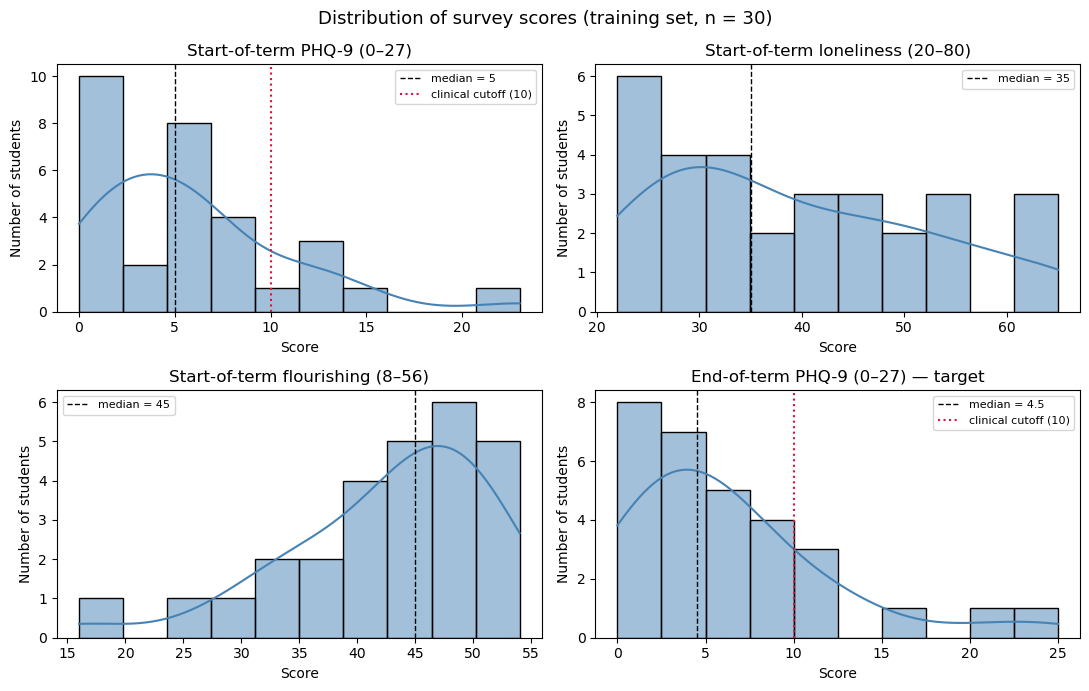

In [125]:
# Distributions of each score (training data)
import matplotlib.pyplot as plt
import seaborn as sns

plot_info = {
    "phq9_pre": "Start-of-term PHQ-9 (0–27)",
    "loneliness_pre": "Start-of-term loneliness (20–80)",
    "flourishing_pre": "Start-of-term flourishing (8–56)",
    "phq9_post": "End-of-term PHQ-9 (0–27) — target",
}

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (column, label) in zip(axes.flat, plot_info.items()):
    sns.histplot(student_train[column].dropna(), bins=10, kde=True, ax=ax, color="steelblue")
    ax.axvline(student_train[column].median(), color="black", linestyle="--", linewidth=1,
               label=f"median = {student_train[column].median():g}")
    if column.startswith("phq9"):
        ax.axvline(10, color="crimson", linestyle=":", linewidth=1.5, label="clinical cutoff (10)")
    ax.set_title(label)
    ax.set_xlabel("Score")
    ax.set_ylabel("Number of students")
    ax.legend(fontsize=8)

fig.suptitle("Distribution of survey scores (training set, n = 30)", fontsize=13)
plt.tight_layout()
plt.show()

**Takeaway:** Both PHQ-9 distributions are concentrated at low scores with a long right tail —
most students report minimal symptoms, and only a few cross the clinical cutoff of 10. This
imbalance is why the at-risk class is small (6 of 30 training students). Flourishing is
concentrated at high scores with a tail of low-wellbeing students, while loneliness is
more evenly spread.

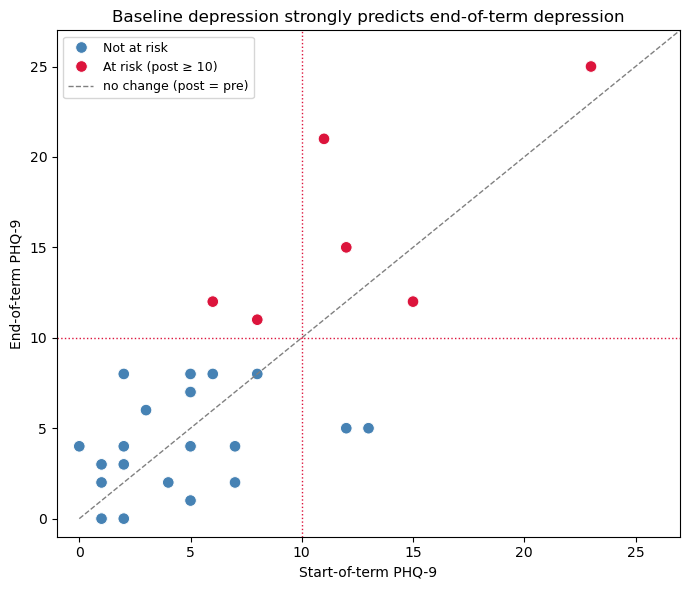

At risk at end,0,1
Flagged at start (pre ≥ 10),,
False,22,2
True,2,4


In [109]:
# Start- vs end-of-term depression, coloured by at-risk status
fig, ax = plt.subplots(figsize=(7, 6))

sns.scatterplot(
    data=student_train, x="phq9_pre", y="phq9_post",
    hue=student_train["at_risk"].map({0: "Not at risk", 1: "At risk (post ≥ 10)"}),
    palette={"Not at risk": "steelblue", "At risk (post ≥ 10)": "crimson"},
    s=70, ax=ax
)
ax.plot([0, 27], [0, 27], color="grey", linestyle="--", linewidth=1, label="no change (post = pre)")
ax.axhline(10, color="crimson", linestyle=":", linewidth=1)
ax.axvline(10, color="crimson", linestyle=":", linewidth=1)

ax.set_xlim(-1, 27)
ax.set_ylim(-1, 27)
ax.set_xlabel("Start-of-term PHQ-9")
ax.set_ylabel("End-of-term PHQ-9")
ax.set_title("Baseline depression strongly predicts end-of-term depression")
ax.legend(title="", fontsize=9)
plt.tight_layout()
plt.show()

# How well would a simple rule ("flag if start-of-term PHQ-9 >= 10") do?
display(pd.crosstab(
    student_train["phq9_pre"] >= 10, student_train["at_risk"],
    rownames=["Flagged at start (pre ≥ 10)"], colnames=["At risk at end"]
))

**Takeaway:** Most students sit close to the "no change" line, so start-of-term depression is a
strong signal for end-of-term depression. But a simple rule (flag every student with PHQ-9 ≥ 10
at the start of term) catches only 4 of the 6 at-risk students in training. It misses two
students (starting at 6 and 8) who **worsened** over the term, and raises two false alarms
(starting at 12–13 but improving to 5). This rule is our **baseline**: a useful model should
catch the students whose symptoms get worse, which is where loneliness and flourishing could
add value.

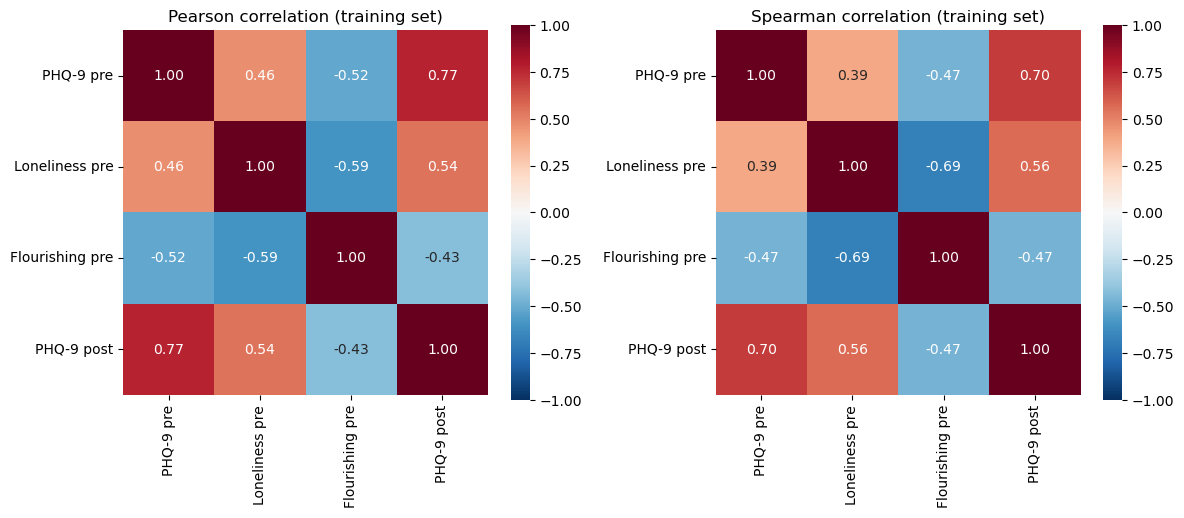

In [110]:
# Correlations between all scores (Pearson and Spearman)
score_columns = ["phq9_pre", "loneliness_pre", "flourishing_pre", "phq9_post"]
labels = ["PHQ-9 pre", "Loneliness pre", "Flourishing pre", "PHQ-9 post"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = student_train[score_columns].corr(method=method)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
                xticklabels=labels, yticklabels=labels, square=True, ax=ax)
    ax.set_title(f"{method.capitalize()} correlation (training set)")

plt.tight_layout()
plt.show()

**Takeaway:** Start-of-term PHQ-9 is the strongest predictor of end-of-term PHQ-9
(Pearson r = 0.77), followed by loneliness (r = 0.54) and flourishing (r = −0.43, higher
wellbeing → fewer symptoms). Spearman correlations, which are less sensitive to the skew
and outliers, tell the same story (0.70, 0.56, −0.47).

The predictors are also correlated **with each other** (|r| = 0.46–0.59): lonelier students
tend to flourish less and report more depressive symptoms. This multicollinearity means
loneliness and flourishing partly overlap with baseline depression, so their *added* value
may be smaller than their individual correlations suggest — the key question of our
research question. It also motivates trying regularized models (Ridge/Lasso), which handle
correlated predictors better than plain linear regression.

In [111]:
# Internal consistency (Cronbach's alpha) of each scale, using training students' item responses
def cronbach_alpha(items):
    """Cronbach's alpha for a DataFrame where each column is one item (rows with missing items dropped)."""
    items = items.dropna()
    k = items.shape[1]
    item_variances = items.var(axis=0, ddof=1).sum()
    total_variance = items.sum(axis=1).var(ddof=1)
    return k / (k - 1) * (1 - item_variances / total_variance), len(items)

train_ids = set(student_train["uid"])

scale_items = {
    "PHQ-9 (9 items)": phq9_clean.loc[
        (phq9_clean["type"] == "pre") & phq9_clean["uid"].isin(train_ids), item_columns
    ].astype(float),
    "UCLA Loneliness (20 items)": loneliness_clean.loc[
        loneliness_clean["uid"].isin(train_ids), loneliness_items
    ].astype(float),
    "Flourishing (8 items)": flourishing_clean.loc[
        flourishing_clean["uid"].isin(train_ids), flourishing_items
    ].astype(float),
}

alpha_rows = []
for scale, items in scale_items.items():
    alpha, n_used = cronbach_alpha(items)
    alpha_rows.append({"scale": scale, "cronbach_alpha": round(alpha, 2), "students_used": n_used})

display(pd.DataFrame(alpha_rows).set_index("scale"))

,cronbach_alpha,students_used
scale,,
PHQ-9 (9 items),0.88,30
UCLA Loneliness (20 items),0.95,30
Flourishing (8 items),0.87,27


In [112]:
# Check whether a log transform reduces the skew of the PHQ-9 scores
import numpy as np

skew_check = pd.DataFrame({
    "original_skew": student_train[["phq9_pre", "phq9_post"]].skew(),
    "log1p_skew": np.log1p(student_train[["phq9_pre", "phq9_post"]]).skew(),
}).round(2)

display(skew_check)

,original_skew,log1p_skew
phq9_pre,1.51,-0.19
phq9_post,1.58,-0.48


### Summary of EDA Learnings

**What we learned**
1. **Baseline depression is the dominant signal.** Start-of-term PHQ-9 correlates r = 0.77
   with end-of-term PHQ-9; loneliness (r = 0.54) and flourishing (r = −0.43) are weaker but
   meaningful.
2. **The predictors overlap.** Loneliness, flourishing and baseline depression are correlated
   with each other (|r| = 0.46–0.59), so their unique contribution beyond baseline PHQ-9 may be
   modest. Testing that added value is our core research question.
3. **A simple rule is a strong baseline but misses students who get worse.** Flagging students
   with PHQ-9 ≥ 10 at the start catches 4 of 6 at-risk students in training and raises 2 false
   alarms. The 2 missed students started below the cutoff and deteriorated.
4. **Scores are skewed and the at-risk class is rare** (6 of 30 training students), so we should
   use metrics robust to imbalance (recall, ROC-AUC) and cross-validation rather than relying
   on the small test set.
5. **Measurement quality is good.** All three scales have Cronbach's α ≥ 0.87, and all values lie
   within their valid ranges. The extreme scores are real responses, not errors.

**Promising transformations**
- **Log transform of PHQ-9 scores:** reduces skew from ~1.5 to near 0. We will treat
  it as a pipeline option and compare with and without it during model selection.
- **Standardization** of all predictors, since they are on different scales (0–27, 20–80, 8–56).
  This is required for regularized models, k-NN and SVMs.
- **Imputation** of the 3 missing flourishing totals, fit on training data only.

**Extra data that would help**
- **A larger sample.** With 38 students (7 at risk), all estimates are noisy; this is a pilot.
- **Mid-term check-ins** (StudentLife's EMA surveys), to catch students who deteriorate mid-term.
- **Passive sensing or wearable data** (sleep, activity, conversation time), available in
  StudentLife and in larger datasets such as GLOBEM, which may capture changes that a one-time
  survey misses.
- **Context variables** such as academic workload, year of study, or major events during the term.

## Prepare the Data

We separate predictors from the two targets. The at-risk label is derived from `phq9_post`, so
neither target is ever used as a predictor (that would be data leakage).

In [114]:
# Separate predictors and targets (training and test sets)
feature_columns = ["phq9_pre", "loneliness_pre", "flourishing_pre"]

X_train = train_data[feature_columns].copy()
X_test = test_data[feature_columns].copy()

y_train_score = train_data["phq9_post"].copy()   # regression target (0–27)
y_test_score = test_data["phq9_post"].copy()

y_train_risk = train_data["at_risk"].copy()      # classification target (1 = PHQ-9 post >= 10)
y_test_risk = test_data["at_risk"].copy()

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (30, 3) | X_test: (8, 3)


All preprocessing is wrapped in a scikit-learn `Pipeline`, so it is learned from training data
only and automatically re-fit inside each cross-validation fold:

| Feature | Steps | Why |
|---|---|---|
| `phq9_pre` | optional `log1p` → standardize | Right-skewed (skew 1.5 → −0.2 after log); the log is a switch so we can test both versions as a hyperparameter |
| `loneliness_pre` | standardize | Roughly symmetric, no missing values |
| `flourishing_pre` | median imputation → standardize | 3 missing totals; the median is robust to the skew and low outlier |

Standardizing puts all scales (0–27, 20–80, 8–56) on the same footing, which regularized models,
k-NN and SVMs require. We do not remove outliers: the extreme scores are real students and are
exactly the cases a screening tool must detect.

In [115]:
# Reusable, leak-free preprocessing pipeline
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

def make_preprocessor(log_phq9=True):
    """
    Build the preprocessing steps applied before any model.

    - phq9_pre: optional log1p transform (reduces right skew), then standardize
    - loneliness_pre: standardize
    - flourishing_pre: impute missing totals with the training median, then standardize

    Because these steps live inside a Pipeline, they are re-fit on the training folds only
    during cross-validation, so no information from validation or test students leaks in.
    """
    phq9_steps = [("scale", StandardScaler())]
    if log_phq9:
        phq9_steps.insert(0, ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))

    return ColumnTransformer([
        ("phq9", Pipeline(phq9_steps), ["phq9_pre"]),
        ("loneliness", StandardScaler(), ["loneliness_pre"]),
        ("flourishing", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), ["flourishing_pre"]),
    ])

In [116]:
# Sanity check: fit on training data only, then inspect the transformed features
preprocessor = make_preprocessor(log_phq9=True)
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)   # transform only — never fit on test

prepared_check = pd.DataFrame(
    X_train_prepared, columns=preprocessor.get_feature_names_out()
)
print("Missing values after preprocessing:", int(np.isnan(X_train_prepared).sum()))
display(prepared_check.describe().loc[["mean", "std"]].round(2))
print("Flourishing median used for imputation:",
      preprocessor.named_transformers_["flourishing"].named_steps["impute"].statistics_[0])

Missing values after preprocessing: 0


,phq9__phq9_pre,loneliness__loneliness_pre,flourishing__flourishing_pre
mean,0.00,0.00,0.00
std,1.02,1.02,1.02


Flourishing median used for imputation: 45.0
